# VAR iş hattı — Faz 0–4 raporu

Bu defter, şekil-önceliğine dayalı GT-free segmentasyon-kalite kestirimi hattına VAR
(Visual Autoregressive) bileşenlerinin eklenmesini dört faz hâlinde raporlar. Her faz,
**reconstruction başarısı değil, kalite-kestirim (QC) başarısı** üzerinden değerlendirilir:
bozulma şiddeti arttıkça modelin ürettiği skorun gerçek Dice ile ne kadar uyumlu düştüğü
(Spearman ρ) esas ölçüttür.

Tüm sonuçlar **test bölünmesinde**, sabit protokolle üretilir: `seed=42`, her temiz maske için
`n_per_mask=5` rastgele bozulma, 3B primitifler (erode, dilate, remove_blob,
add_false_positive, boundary_noise, translate). Sayılar kayıtlı JSON'lardan değil, **diskteki
checkpoint'lerden canlı** yeniden hesaplanır.

**Fazlar**
- **Faz 0** — Kapsam, ilke ve değerlendirme protokolü.
- **Faz 1** — Çok-ölçekli artık VQ (VAR tokenizer) ↔ tek-ölçekli VQ taban çizgisi (reconstruction QC).
- **Faz 2** — Eq.(5) GAN terimi (3B PatchGAN) reconstruction QC'yi iyileştiriyor mu?
- **Faz 3** — VAR omurgası üzerinde FP/FN ikili-baş (est_dice ρ + ASSD).
- **Faz 4** — Ardışık (cascade) ikinci VAE: referans maske doğruluğu ↔ QC.

## Faz 0 — Kapsam, ilke ve değerlendirme protokolü

**İlke.** Hat boyunca tekrar eden gözlem: *en iyi reconstruction, en iyi QC demek değildir.*
Bir model maskeleri çok iyi geri çatabilir ama ürettiği hata sinyali gerçek kalite ile zayıf
ilişkilenebilir (kimlik-tuzağı). Bu yüzden her faz, birincil olarak QC metriği (skor ↔ gerçek
Dice korelasyonu) ile karşılaştırılır; reconstruction yalnızca ikincil bir gözlemdir.

**Değerlendirme kümesi.** İki ayrı küme, aynı protokolle:
- *Maske-only* (Faz 1–2): yalnızca ikili maske girişi alan reconstruction modelleri için.
- *Görüntü+maske* (Faz 3–4): `[BT görüntü, bozuk maske]` girişi alan FP/FN ve cascade modelleri için.

İki küme de test bölünmesinde, `seed=42`, `n_per_mask=5` ile kurulur; böylece fazlar arası
sayılar aynı bozulma dağılımı üzerinde okunur.

In [1]:
import os
# Windows'ta numpy-MKL + torch-OpenMP çift yüklemesi kernel'i düşürebiliyor; önce bunu kur.
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')

import sys, json, logging
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print('PROJECT_ROOT =', PROJECT_ROOT)

from data import load_config
from data.degradations import dice as _dice
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D
from data.fpfn_targets import correct_mask, estimated_dice, error_volume
from quality.score import correlation, banded_correlation
from quality.surface_metrics import assd
from train import resolve_device, set_seed

import evaluate_correlation_3d as ev3d
import evaluate_correlation_3d_vq as evq
import evaluate_correlation_3d_var as evv
import evaluate_correlation_imgcond as evic
import evaluate_correlation_imgcond_fpfn as evfpfn

# train/evaluate_* import ederken matplotlib Agg'e geçiyor; inline'ı importlardan SONRA kur.
%matplotlib inline

SEED = 42
device = resolve_device('auto')
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'
ALL_FNS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
print('device =', device)
print('standart primitifler :', ', '.join(PRIMITIVES_3D))
print('partial primitifler  :', ', '.join(PARTIAL_PRIMITIVES_3D))

PROJECT_ROOT = C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
device = cuda
standart primitifler : erode, dilate, remove_blob, add_false_positive, boundary_noise, translate
partial primitifler  : heavy_erode, center_only, partial


### Ortak değerlendirme kümelerinin kurulumu

İki küme de aynı tohum ve `n_per_mask` ile kurulur. Maske-only küme `vae3d_var.yaml`
(önceden hesaplanmış `outputs/volumes`) üzerinden; görüntü+maske küme `vae3d_imgcond_fpfn.yaml`
(`outputs/image_volumes`) üzerinden gelir. Bozulma aralıkları her kümede ayrı kalibre edilir.

In [2]:
N_PER_MASK = 5

# --- Maske-only küme (Faz 1-2 reconstruction modelleri) ---
cfg_recon = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_var.yaml'))
cfg_recon.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)
clean_masks_r = ev3d.load_clean_volumes(cfg_recon, 'test', None, SEED)
degrader_r = ev3d.calibrate_degrader(cfg_recon, clean_masks_r, SEED)
masks_r, true_dice_r, is_clean_r = ev3d.build_eval_set(clean_masks_r, degrader_r, N_PER_MASK, SEED)
is_clean_r = np.asarray(is_clean_r, dtype=bool)
print(f'[maske-only] hasta={len(clean_masks_r)}  hacim={len(masks_r)} '
      f'({is_clean_r.sum()} temiz + {(~is_clean_r).sum()} bozuk)  şekil={masks_r.shape[1:]}')

# --- Görüntü+maske küme (Faz 3-4 FP/FN & cascade) ---
cfg_img = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_imgcond_fpfn.yaml'))
cfg_img.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)
clean_masks, clean_images = evic.load_clean_image_volumes(cfg_img, 'test', None, SEED)
degrader = ev3d.calibrate_degrader(cfg_img, clean_masks, SEED)
broken, images, clean_ref, true_dice, is_clean = evfpfn.build_eval_set_fpfn(
    clean_masks, clean_images, degrader, N_PER_MASK, SEED)
is_clean = np.asarray(is_clean, dtype=bool)
print(f'[görüntü+maske] hasta={len(clean_masks)}  hacim={len(broken)} '
      f'({is_clean.sum()} temiz + {(~is_clean).sum()} bozuk)  şekil={broken.shape[1:]}')
print('kalibre bozulma aralıkları (görüntü+maske):')
for k, v in (degrader.type_ranges or {}).items():
    print(f'    {k:18s} Dice ∈ [{v[0]:.2f}, {v[1]:.2f}]')

[maske-only] hasta=47  hacim=282 (47 temiz + 235 bozuk)  şekil=(64, 64, 64)
[görüntü+maske] hasta=47  hacim=282 (47 temiz + 235 bozuk)  şekil=(64, 64, 64)
kalibre bozulma aralıkları (görüntü+maske):
    erode              Dice ∈ [0.00, 0.94]
    dilate             Dice ∈ [0.42, 0.94]
    remove_blob        Dice ∈ [0.80, 1.00]
    add_false_positive Dice ∈ [0.86, 0.99]
    boundary_noise     Dice ∈ [0.49, 1.00]
    translate          Dice ∈ [0.19, 0.96]


## Faz 1 — VAR tokenizer ↔ VQ taban çizgisi (reconstruction QC)

VAR'ın birinci-aşama tokenizer'ı **çok-ölçekli artık** bir VQ-VAE'dir: darboğaz ızgarasını tek
seferde kod defterine oturtmak yerine, öznitelik haritasını kaba→ince ölçeklerde kodlar. Her
ölçekte artık (residual) `pn³`'e indirgenir, paylaşılan kod defterine oturtulur, tam çözünürlüğe
geri yükseltilir, küçük bir `Phi` konvolüsyonu ile düzeltilip biriktirilir ve artıktan çıkarılır.

Encoder/decoder gövdesi `ConvVQVAE3D` ile **birebir aynı** tutulmuştur; tek fark darboğazdaki
quantizer'dır. Böylece karşılaştırma yalnızca *tek-ölçekli VQ ↔ çok-ölçekli artık VQ* farkını
yalıtır. Birincil QC skoru `recon_dice` (yeniden-çatılan maskenin girdiyle Dice'ı); ikincil
skor `quant_error` (darboğaz artık enerjisi).

In [3]:
RECON_REGISTRY = [
    ('VQ (taban)', 'vq',  evq),   # tek-ölçekli VQ
    ('VAR',        'var', evv),   # çok-ölçekli artık VQ
]
recon_results = {}
for lbl, tag, mod in RECON_REGISTRY:
    path = CKPT / f'vae3d_{tag}_best.pt'
    if not path.exists():
        print('YOK, atlanıyor:', lbl, path.name); continue
    model = mod.load_model(path, device)
    scorer = mod.score_masks_vq if hasattr(mod, 'score_masks_vq') else mod.score_masks_var
    summ = mod.summarise_vq if hasattr(mod, 'summarise_vq') else mod.summarise_var
    scores = scorer(model, masks_r, device)
    summary = summ(scores, true_dice_r)
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    recon_results[lbl] = dict(scores=scores, summary=summary, model=model,
                              epoch=ckpt.get('epoch'), path=str(path))
    rd = summary['recon_dice']['global']['spearman']
    qe = summary.get('quant_error', {}).get('global', {}).get('spearman')
    qe_s = f'{qe:+.3f}' if qe is not None else 'n/a'
    print(f'{lbl:12s} recon_dice ρ={rd:+.3f}  quant_error ρ={qe_s}  (epoch {ckpt.get("epoch")})')

YOK, atlanıyor: VQ (taban) vae3d_vq_best.pt
VAR          recon_dice ρ=+0.866  quant_error ρ=-0.598  (epoch 80)


In [4]:
# Faz 1 özet tablo: QC skorlarının global ρ'su
import pandas as pd
rows = []
for lbl, *_ in RECON_REGISTRY:
    if lbl not in recon_results: continue
    s = recon_results[lbl]['summary']
    row = {'model': lbl, 'epoch': recon_results[lbl]['epoch']}
    for name in s:
        g = s[name]['global']
        row[f'{name} ρ'] = round(g['spearman'], 3)
    rows.append(row)
df_recon = pd.DataFrame(rows)
display(df_recon)
print('Not: recon_dice birincil QC skoru; quant_error ikincil (darboğaz artık enerjisi).')

Not: recon_dice birincil QC skoru; quant_error ikincil (darboğaz artık enerjisi).


,model,epoch,recon_dice ρ,recon_bce ρ,recon_l1 ρ,topology ρ,quant_error ρ
0,VAR,80,0.866,-0.541,-0.495,-0.157,-0.598


### Faz 1 — hasta bazında reconstruction, hafif → ağır bozulma

Tek bir hasta seçilip üç bozulma seviyesinde (hafif/orta/ağır) bozulur; her iki model
(VQ ve VAR) aynı bozuk girdiyi yeniden çatar. `recon_dice` = yeniden-çatılan maskenin **girdi
ile** Dice'ı (GT-free sinyal); gerçek kalite ile kıyas için gerçek Dice de gösterilir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz1_panel.png


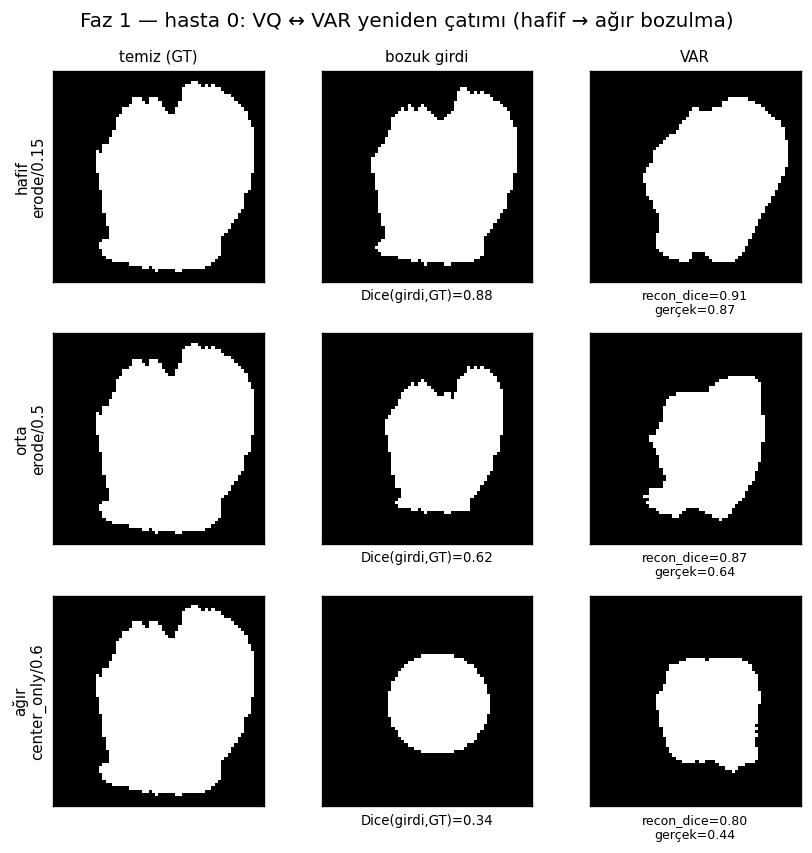

In [5]:
PANEL_IDX = 0
panel_gt_r = clean_masks_r[PANEL_IDX].astype(bool)
# üç seviye: gerçek Dice'ı hedefe en yakın bozulmaları seç
_cands = []
for name, sev in [('erode', 0.15), ('erode', 0.3), ('erode', 0.5), ('dilate', 0.4),
                  ('heavy_erode', 0.3), ('center_only', 0.4), ('center_only', 0.6), ('center_only', 0.75)]:
    b = np.asarray(ALL_FNS[name](panel_gt_r, sev, np.random.default_rng(SEED))) > 0
    if 0 < int(b.sum()) < panel_gt_r.size:
        _cands.append((b, float(_dice(panel_gt_r, b)), f'{name}/{sev}'))
levels = []
_used = []
for target, lvl in [(0.85, 'hafif'), (0.65, 'orta'), (0.45, 'ağır')]:
    k = min((j for j in range(len(_cands)) if j not in _used), key=lambda j: abs(_cands[j][1] - target))
    _used.append(k); levels.append((_cands[k][0], _cands[k][1], lvl, _cands[k][2]))

@torch.no_grad()
def recon_mask(model, mask):
    x = torch.from_numpy(mask.astype('float32')[None, None]).to(device)
    out = model.reconstruct(x)
    return out[0, 0].cpu().numpy() > 0.5

labels_r = [l for l, *_ in RECON_REGISTRY if l in recon_results]
zc = panel_gt_r.shape[0] // 2
ncol = 2 + len(labels_r)
fig, axes = plt.subplots(len(levels), ncol, figsize=(2.4 * ncol, 2.4 * len(levels)), squeeze=False)
for ri, (brk, d_in, lvl, nm) in enumerate(levels):
    axes[ri, 0].imshow(panel_gt_r[zc], cmap='gray')
    axes[ri, 1].imshow(brk[zc], cmap='gray')
    for ci, lbl in enumerate(labels_r):
        rec = recon_mask(recon_results[lbl]['model'], brk)
        d_rec_in = float(_dice(brk, rec)); d_rec_gt = float(_dice(panel_gt_r, rec))
        axes[ri, 2 + ci].imshow(rec[zc], cmap='gray')
        axes[ri, 2 + ci].set_xlabel(f'recon_dice={d_rec_in:.2f}\ngerçek={d_rec_gt:.2f}', fontsize=7.5)
    for ci in range(ncol):
        axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
    axes[ri, 0].set_ylabel(f'{lvl}\n{nm}', fontsize=9)
    axes[ri, 1].set_xlabel(f'Dice(girdi,GT)={d_in:.2f}', fontsize=8)
cols = ['temiz (GT)', 'bozuk girdi'] + labels_r
for ci, t in enumerate(cols):
    axes[0, ci].set_title(t, fontsize=9)
fig.suptitle(f'Faz 1 — hasta {PANEL_IDX}: VQ ↔ VAR yeniden çatımı (hafif → ağır bozulma)', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz1_panel.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## Faz 2 — Eq.(5) GAN terimi (reconstruction QC)

VAR kaybının Eq.(5) terimi bir çekişmeli (adversarial) bileşen içerir. İkili maskelerde LPIPS ve
öznitelik-L2 anlamsız olduğundan yalnızca `λ_G·L_GAN` terimi eklendi: 3B PatchGAN ayırıcı, hinge
amaç fonksiyonu, ve ilk birkaç epoch yalnız recon+VQ ile ısınma (warmup). İki koşu karşılaştırılır:
güçlü ayırıcı (`vargan`) ve dengeli/zayıflatılmış ayırıcı (`vargan_bal`).

Buradaki soru: GAN terimi reconstruction QC'yi (recon_dice ρ) Faz 1'deki düz VAR'ın üzerine
çıkarıyor mu? (Ayırıcının validation `d_loss`'u değerlendirme geçişinde eğitilmediği için daima 0'dır;
kanıt recon_dice ρ'dur, d_loss değil.)

In [6]:
GAN_REGISTRY = [
    ('VAR (Faz1)',     'var'),         # referans
    ('VAR+GAN',        'vargan'),      # güçlü ayırıcı
    ('VAR+GAN dengeli','vargan_bal'),  # zayıflatılmış ayırıcı
]
gan_results = {}
for lbl, tag in GAN_REGISTRY:
    path = CKPT / f'vae3d_{tag}_best.pt'
    if not path.exists():
        print('YOK, atlanıyor:', lbl, path.name); continue
    model = evv.load_model(path, device)   # GAN jeneratörü VAR mimarisidir, eval-uyumlu
    scores = evv.score_masks_var(model, masks_r, device)
    summary = evv.summarise_var(scores, true_dice_r)
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    gan_results[lbl] = dict(summary=summary, epoch=ckpt.get('epoch'), path=str(path))
    rd = summary['recon_dice']['global']['spearman']
    qe = summary.get('quant_error', {}).get('global', {}).get('spearman')
    qe_s = f'{qe:+.3f}' if qe is not None else 'n/a'
    print(f'{lbl:18s} recon_dice ρ={rd:+.3f}  quant_error ρ={qe_s}  (epoch {ckpt.get("epoch")})')

rows = []
for lbl, tag in GAN_REGISTRY:
    if lbl not in gan_results: continue
    s = gan_results[lbl]['summary']
    rows.append({'model': lbl, 'epoch': gan_results[lbl]['epoch'],
                 'recon_dice ρ': round(s['recon_dice']['global']['spearman'], 3),
                 'quant_error ρ': round(s.get('quant_error', {}).get('global', {}).get('spearman', float('nan')), 3)})
display(pd.DataFrame(rows))
print('Gözlem: dengeli GAN recon_dice ρ\'yu en fazla marjinal oynatır; quant_error QC zayıflar. '
      'Reconstruction-tarafı QC ~0.86-0.87 platosundadır.')

VAR (Faz1)         recon_dice ρ=+0.866  quant_error ρ=-0.598  (epoch 80)
VAR+GAN            recon_dice ρ=+0.844  quant_error ρ=-0.353  (epoch 19)
VAR+GAN dengeli    recon_dice ρ=+0.873  quant_error ρ=-0.358  (epoch 24)
Gözlem: dengeli GAN recon_dice ρ'yu en fazla marjinal oynatır; quant_error QC zayıflar. Reconstruction-tarafı QC ~0.86-0.87 platosundadır.


,model,epoch,recon_dice ρ,quant_error ρ
0,VAR (Faz1),80,0.866,-0.598
1,VAR+GAN,19,0.844,-0.353
2,VAR+GAN dengeli,24,0.873,-0.358


## Faz 3 — VAR omurgası üzerinde FP/FN ikili-baş (est_dice ρ + ASSD)

FP/FN ikili-baş, girdi olarak `[BT görüntü, bozuk maske]` alıp iki düzeltme haritası üretir:
**FP** (silinecek voksel = `bozuk ∧ ¬temiz`) ve **FN** (eklenecek voksel = `temiz ∧ ¬bozuk`).
Hedefler bozuk maskeye *göreli* tanımlandığından model maske kanalını yok sayamaz. GT-free kalite
skoru `est_dice` (bozuk maskenin tahmini Dice'ı); kenar hatası ise ASSD ile ölçülür.

Burada VAR omurgalı FP/FN (`g_var`), mevcut düz-VQ/SimVQ FP/FN varyantlarıyla karşılaştırılır.

In [7]:
FPFN_REGISTRY = [
    ('G-ikili/VQ',    'g_vq',          'binary', 'vq',    'vq'),
    ('G-ikili/SimVQ', 'g_simvq',       'binary', 'simvq', 'vq'),
    ('G-SDF/VQ',      'g_sdfio_vq',    'sdfio',  'vq',    'vq'),
    ('G-SDF/SimVQ',   'g_sdfio_simvq', 'sdfio',  'simvq', 'vq'),
    ('G-VAR/ikili',   'g_var',         'binary', 'vq',    'var'),  # Faz 3 — VAR omurga
]
fns, dirs = evfpfn.build_score_registry()
fpfn_results = {}
for lbl, tag, head, quant, backbone in FPFN_REGISTRY:
    path = CKPT / f'vae3d_{tag}_best.pt'
    if not path.exists():
        print('YOK, atlanıyor:', lbl); continue
    if backbone == 'var':
        import evaluate_correlation_var_fpfn as evvf
        model = evvf.load_var_fpfn_model(path, device)
    else:
        model = evfpfn.load_fpfn_model(path, head, quant, device)
    scores = evfpfn.score_masks_fpfn(model, broken, images, fns, device)
    summary = evfpfn.summarise(scores, true_dice, dirs)
    assd_stats = evfpfn.compute_assd_improvement(model, broken, images, clean_ref, is_clean, device)
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    fpfn_results[lbl] = dict(scores=scores, summary=summary, assd=assd_stats, model=model,
                             head=head, quantizer=quant, backbone=backbone, epoch=ckpt.get('epoch'))
    ed = summary['est_dice']['global']['spearman']
    print(f'{lbl:16s} [{backbone:3s}] est_dice ρ={ed:+.3f}  '
          f'ASSD {assd_stats["assd_input_mean"]:.2f}->{assd_stats["assd_corrected_mean"]:.2f} '
          f'(azalma {assd_stats["assd_reduction"]:.3f})  (epoch {ckpt.get("epoch")})')

G-ikili/VQ       [vq ] est_dice ρ=+0.948  ASSD 3.24->1.87 (azalma 1.373)  (epoch 44)
G-ikili/SimVQ    [vq ] est_dice ρ=+0.956  ASSD 3.24->1.71 (azalma 1.533)  (epoch 44)
G-SDF/VQ         [vq ] est_dice ρ=+0.930  ASSD 3.24->1.98 (azalma 1.264)  (epoch 42)
G-SDF/SimVQ      [vq ] est_dice ρ=+0.943  ASSD 3.24->1.84 (azalma 1.401)  (epoch 44)
G-VAR/ikili      [var] est_dice ρ=+0.962  ASSD 3.24->1.55 (azalma 1.690)  (epoch 48)


In [8]:
# Faz 3 özet tablo: est_dice ρ + ASSD azalma
rows = []
for lbl, tag, head, quant, backbone in FPFN_REGISTRY:
    if lbl not in fpfn_results: continue
    r = fpfn_results[lbl]; s = r['summary']; a = r['assd']
    rows.append({'model': lbl, 'omurga': backbone,
                 'est_dice ρ': round(s['est_dice']['global']['spearman'], 3),
                 'est_dice Pearson': round(s['est_dice']['global']['pearson'], 3),
                 'error_volume ρ': round(s['error_volume']['global']['spearman'], 3),
                 'ASSD girdi': round(a['assd_input_mean'], 3),
                 'ASSD düzelt': round(a['assd_corrected_mean'], 3),
                 'ASSD azalma': round(a['assd_reduction'], 3)})
df_fpfn = pd.DataFrame(rows).sort_values('est_dice ρ', ascending=False).reset_index(drop=True)
display(df_fpfn)

,model,omurga,est_dice ρ,est_dice Pearson,error_volume ρ,ASSD girdi,ASSD düzelt,ASSD azalma
0,G-VAR/ikili,var,0.962,0.962,-0.912,3.243,1.553,1.690
1,G-ikili/SimVQ,vq,0.956,0.941,-0.901,3.243,1.710,1.533
2,G-ikili/VQ,vq,0.948,0.936,-0.910,3.243,1.870,1.373
3,G-SDF/SimVQ,vq,0.943,0.913,-0.897,3.243,1.842,1.401
4,G-SDF/VQ,vq,0.930,0.901,-0.899,3.243,1.979,1.264


### Faz 3 — tek hasta, tüm FP/FN modelleri (bağımsız çalışan hücre)

Yalnızca `PATIENT_IDX` ve `TARGET_DICE` değiştirilerek tek hastada tüm modellerin tahmin ettiği
FP/FN haritaları ve düzeltilmiş maske karşılaştırılır. Aynı bozuk girdi tüm modellere verilir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz3_hasta0.png


,model,Dice girdi (GT),est_dice (tahmin),Dice düzelt (GT),error_volume,ASSD girdi,ASSD düzelt
0,G-ikili/VQ,0.621,0.685,0.796,38511,5.1,2.53
1,G-ikili/SimVQ,0.621,0.663,0.793,40904,5.1,2.64
2,G-SDF/VQ,0.621,0.742,0.775,30789,5.1,2.75
3,G-SDF/SimVQ,0.621,0.754,0.757,26626,5.1,2.74
4,G-VAR/ikili,0.621,0.678,0.796,39007,5.1,2.71


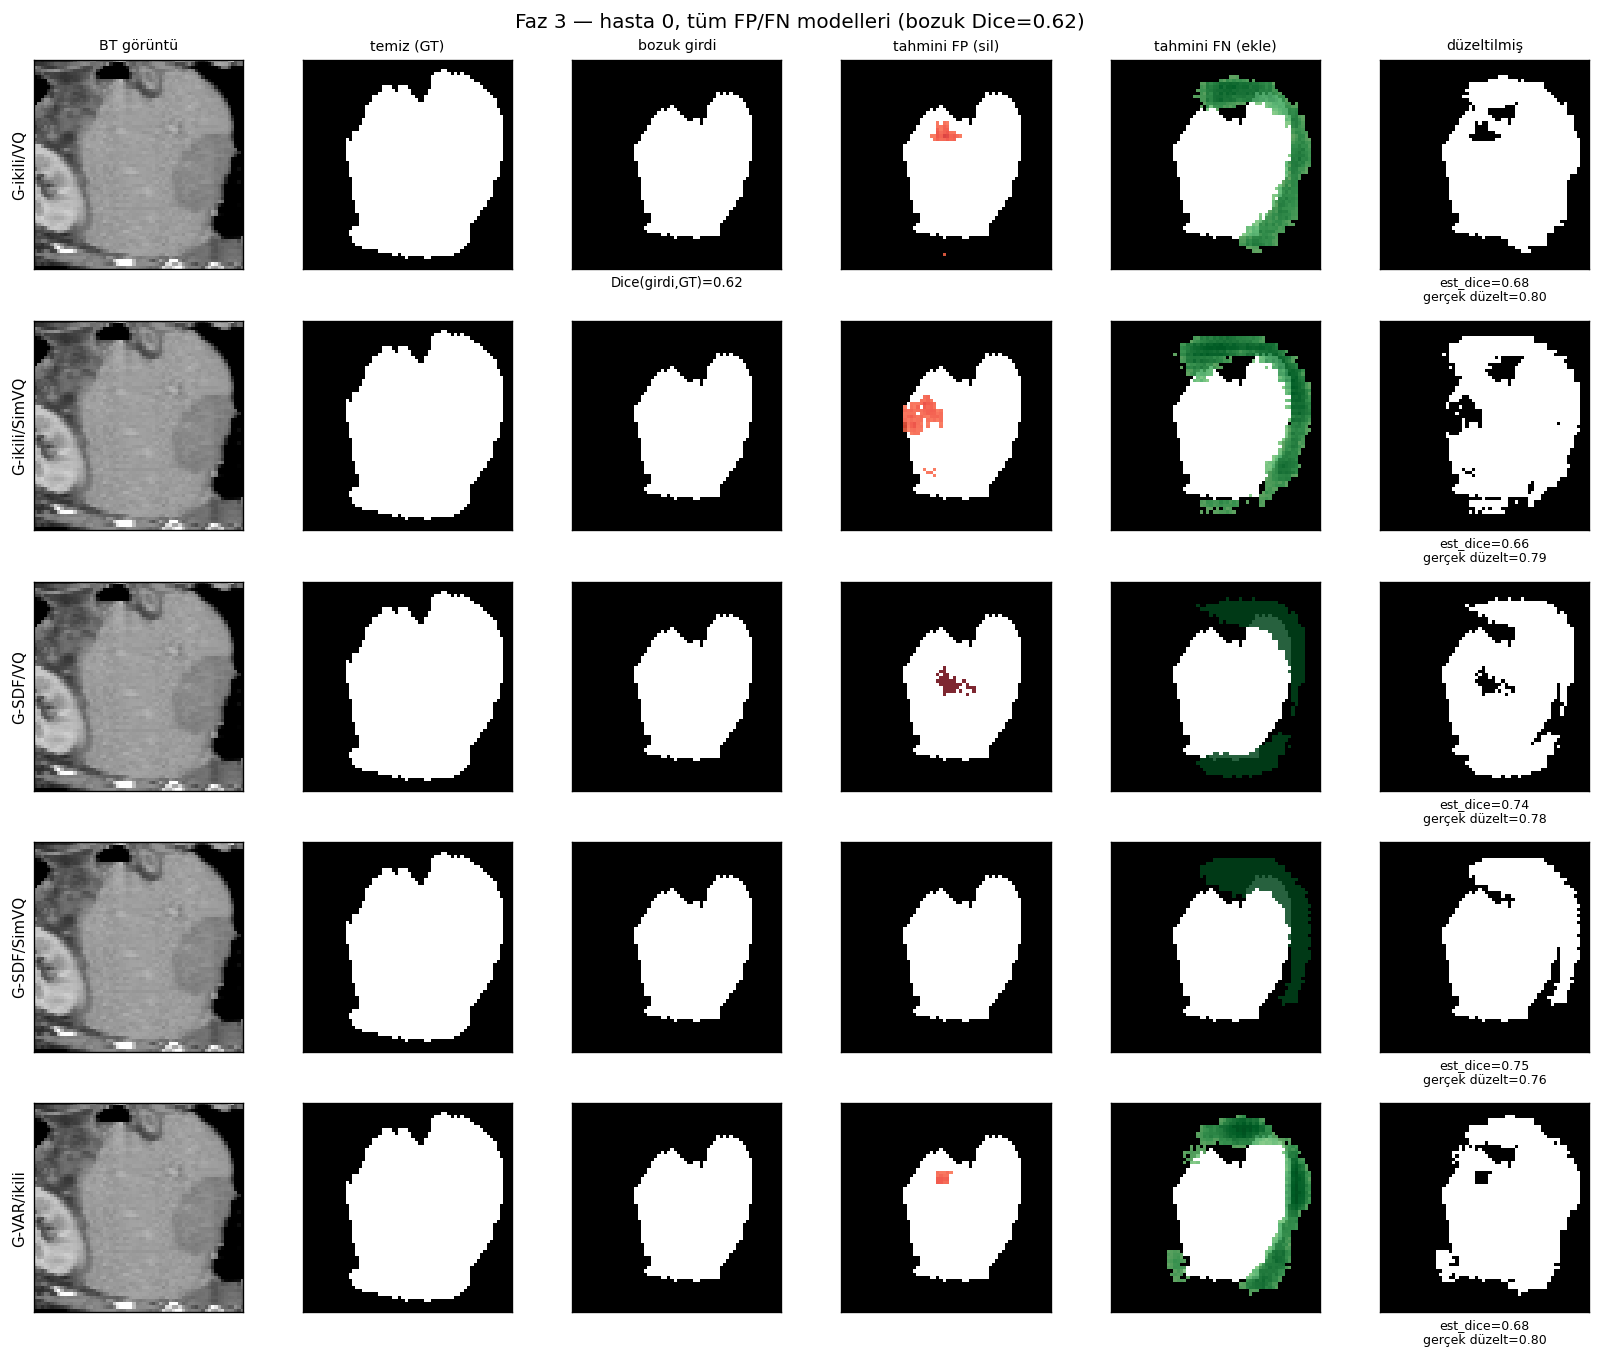

In [9]:
PATIENT_IDX = 0
TARGET_DICE = 0.6

_gt = clean_masks[PATIENT_IDX].astype(bool)
_img = clean_images[PATIENT_IDX]
_brk, _d_in = degrader.make_pair(_gt, np.random.default_rng(SEED + PATIENT_IDX), target_dice=TARGET_DICE)
_brk = np.asarray(_brk) > 0
_assd_in = assd(_brk, _gt)

@torch.no_grad()
def maps_one(model, image, mask):
    x = torch.from_numpy(np.stack([image, mask.astype('float32')])[None]).float().to(device)
    fp, fn = model.predict_fpfn(x)
    corr = correct_mask(x[:, 1:2], fp, fn)
    ed = float(estimated_dice(x[:, 1:2], fp, fn)[0]); ev = float(error_volume(fp, fn)[0])
    return fp[0, 0].cpu().numpy(), fn[0, 0].cpu().numpy(), corr[0, 0].cpu().numpy() > 0.5, ed, ev

labels_f = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
zc = _gt.shape[0] // 2
cols = ['BT görüntü', 'temiz (GT)', 'bozuk girdi', 'tahmini FP (sil)', 'tahmini FN (ekle)', 'düzeltilmiş']
fig, axes = plt.subplots(len(labels_f), len(cols), figsize=(2.3 * len(cols), 2.3 * len(labels_f)), squeeze=False)
prows = []
for ri, lbl in enumerate(labels_f):
    fp, fn, comp, ed, ev = maps_one(fpfn_results[lbl]['model'], _img, _brk)
    d_comp = float(_dice(_gt, comp)); assd_co = assd(comp, _gt)
    prows.append({'model': lbl, 'Dice girdi (GT)': round(_d_in, 3), 'est_dice (tahmin)': round(ed, 3),
                  'Dice düzelt (GT)': round(d_comp, 3), 'error_volume': int(ev),
                  'ASSD girdi': round(float(_assd_in), 2), 'ASSD düzelt': round(float(assd_co), 2)})
    axes[ri, 0].imshow(_img[zc], cmap='gray'); axes[ri, 1].imshow(_gt[zc], cmap='gray')
    axes[ri, 2].imshow(_brk[zc], cmap='gray')
    axes[ri, 3].imshow(_brk[zc], cmap='gray')
    axes[ri, 3].imshow(np.ma.masked_where(fp[zc] <= 0.5, fp[zc]), cmap='Reds', vmin=0, vmax=1, alpha=0.85)
    axes[ri, 4].imshow(_brk[zc], cmap='gray')
    axes[ri, 4].imshow(np.ma.masked_where(fn[zc] <= 0.5, fn[zc]), cmap='Greens', vmin=0, vmax=1, alpha=0.85)
    axes[ri, 5].imshow(comp[zc], cmap='gray')
    for ci in range(len(cols)):
        axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
        if ri == 0: axes[ri, ci].set_title(cols[ci], fontsize=8.5)
    axes[ri, 0].set_ylabel(lbl, fontsize=9)
    axes[ri, 5].set_xlabel(f'est_dice={ed:.2f}\ngerçek düzelt={d_comp:.2f}', fontsize=7.5)
axes[0, 2].set_xlabel(f'Dice(girdi,GT)={_d_in:.2f}', fontsize=8)
fig.suptitle(f'Faz 3 — hasta {PATIENT_IDX}, tüm FP/FN modelleri (bozuk Dice={_d_in:.2f})', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / f'rapor_var_faz3_hasta{PATIENT_IDX}.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
display(pd.DataFrame(prows))

### Faz 3 — VAR omurgası: hafif → ağır bozulma haritaları

VAR omurgalı FP/FN modelinin tahmin ettiği silme/ekleme haritaları, aynı hastada artan bozulma
şiddetinde incelenir. Bozulma ağırlaştıkça `est_dice` gerçek Dice'ı takip etmelidir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz3_agir_bozulma.png


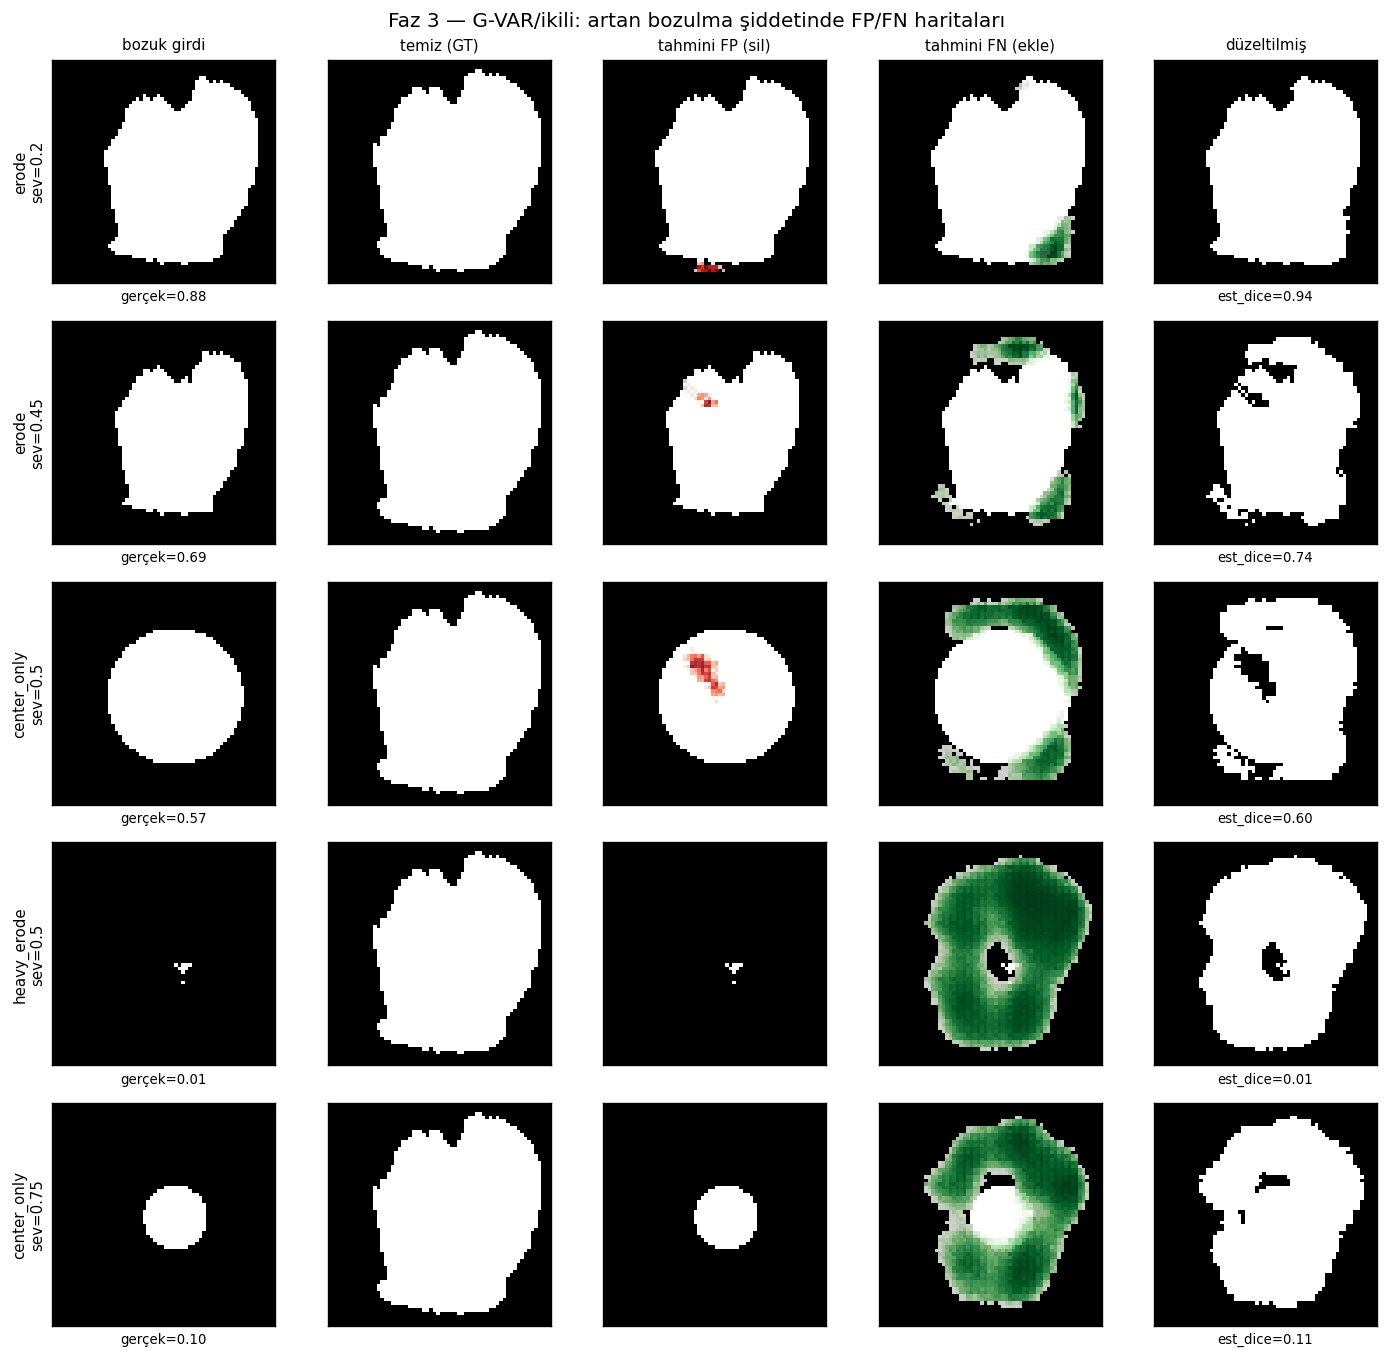

In [10]:
VAR_LBL = 'G-VAR/ikili'
if VAR_LBL in fpfn_results:
    model = fpfn_results[VAR_LBL]['model']
    gt = clean_masks[PANEL_IDX].astype(bool); img = clean_images[PANEL_IDX]
    specs = [('erode', 0.2), ('erode', 0.45), ('center_only', 0.5), ('heavy_erode', 0.5), ('center_only', 0.75)]
    zc = gt.shape[0] // 2
    cols = ['bozuk girdi', 'temiz (GT)', 'tahmini FP (sil)', 'tahmini FN (ekle)', 'düzeltilmiş']
    fig, axes = plt.subplots(len(specs), 5, figsize=(12, 2.3 * len(specs)), squeeze=False)
    for ri, (name, sev) in enumerate(specs):
        b = np.asarray(ALL_FNS[name](gt, sev, np.random.default_rng(SEED))) > 0
        d_true = float(_dice(gt, b))
        fp, fn, comp, ed, ev = maps_one(model, img, b)
        axes[ri, 0].imshow(b[zc], cmap='gray'); axes[ri, 1].imshow(gt[zc], cmap='gray')
        axes[ri, 2].imshow(b[zc], cmap='gray')
        axes[ri, 2].imshow(np.ma.masked_where(fp[zc] <= 0.5, fp[zc]), cmap='Reds', alpha=0.85)
        axes[ri, 3].imshow(b[zc], cmap='gray')
        axes[ri, 3].imshow(np.ma.masked_where(fn[zc] <= 0.5, fn[zc]), cmap='Greens', alpha=0.85)
        axes[ri, 4].imshow(comp[zc], cmap='gray')
        for ci in range(5):
            axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
            if ri == 0: axes[ri, ci].set_title(cols[ci], fontsize=9)
        axes[ri, 0].set_ylabel(f'{name}\nsev={sev}', fontsize=9)
        axes[ri, 0].set_xlabel(f'gerçek={d_true:.2f}', fontsize=8)
        axes[ri, 4].set_xlabel(f'est_dice={ed:.2f}', fontsize=8)
    fig.suptitle(f'Faz 3 — {VAR_LBL}: artan bozulma şiddetinde FP/FN haritaları', fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz3_agir_bozulma.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

### Faz 3 — en zorlu bant [0.40–0.55], çapraz-hasta (dürüst sayı)

Global ρ kolay (yüksek-Dice) örneklerle şişebilir. Tüm hastalarda ağır primitifler taranıp
gerçek Dice'ı [0.40–0.55] bandına düşen örnekler toplanır; bu bantta `est_dice` ↔ gerçek Dice
korelasyonu, modelin gerçekten zor vakalarda ayrıştırma gücünü verir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz3_agir_bant.png


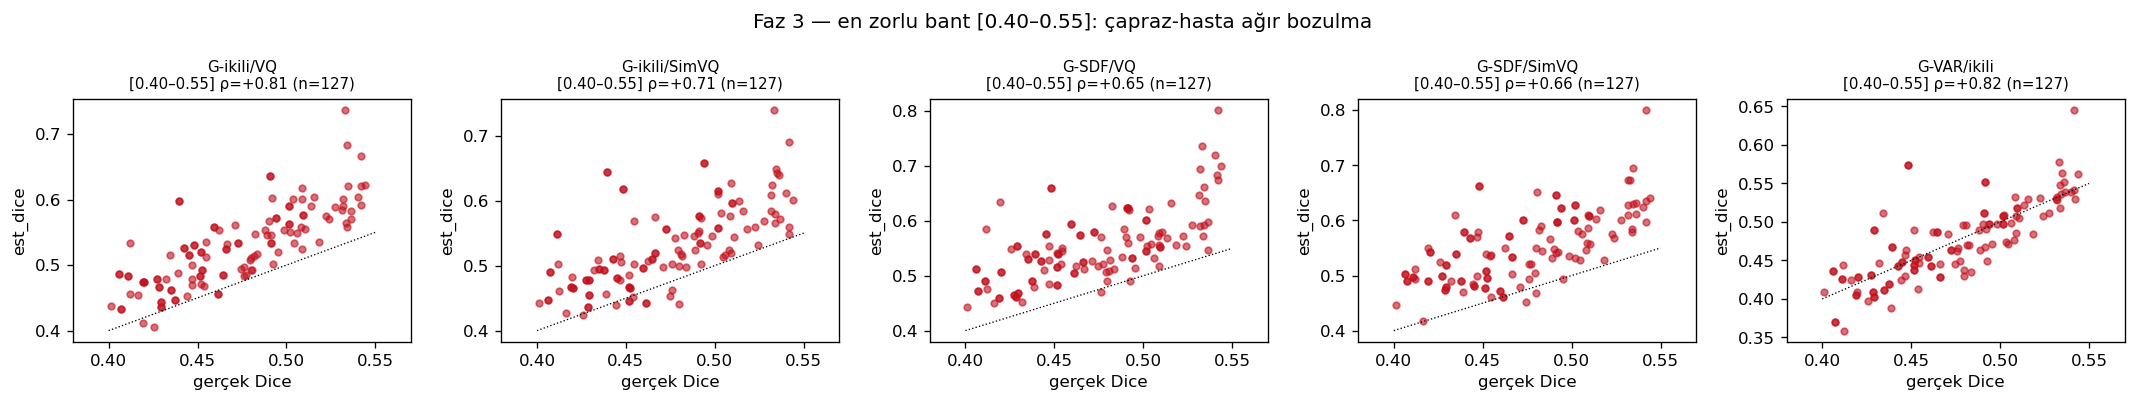

In [11]:
def heavy_probe(model, band=(0.40, 0.55)):
    sweeps = {'center_only': np.linspace(0.40, 0.60, 5),
              'heavy_erode': np.linspace(0.14, 0.24, 5),
              'erode': np.linspace(0.45, 0.80, 6)}
    td, es = [], []
    for pid, (gt_, img_) in enumerate(zip(clean_masks, clean_images)):
        gt_ = gt_.astype(bool)
        for name, sevs in sweeps.items():
            for sev in sevs:
                b = np.asarray(ALL_FNS[name](gt_, float(sev), np.random.default_rng(SEED + pid))) > 0
                if not (0 < int(b.sum()) < gt_.size): continue
                d_true = float(_dice(gt_, b))
                if not (band[0] <= d_true <= band[1]): continue
                x = torch.from_numpy(np.stack([img_, b.astype('float32')])[None]).float().to(device)
                with torch.no_grad():
                    fp, fn = model.predict_fpfn(x)
                    ed = float(estimated_dice(x[:, 1:2], fp, fn)[0])
                td.append(d_true); es.append(ed)
    return np.array(td), np.array(es)

labels_f = [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]
fig, axes = plt.subplots(1, len(labels_f), figsize=(3.6 * len(labels_f), 3.4), squeeze=False)
for ax, lbl in zip(axes[0], labels_f):
    td, es = heavy_probe(fpfn_results[lbl]['model'])
    rho = correlation(es, td)['spearman'] if len(td) >= 3 else float('nan')
    ax.scatter(td, es, s=16, alpha=0.6, c='#c1121f')
    ax.plot([0.40, 0.55], [0.40, 0.55], 'k:', lw=0.8)
    ax.set_xlim(0.38, 0.57); ax.set_xlabel('gerçek Dice'); ax.set_ylabel('est_dice')
    ax.set_title(f'{lbl}\n[0.40–0.55] ρ={rho:+.2f} (n={len(td)})', fontsize=9)
fig.suptitle('Faz 3 — en zorlu bant [0.40–0.55]: çapraz-hasta ağır bozulma', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz3_agir_bant.png'
fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()

## Faz 4 — Ardışık ikinci VAE (cascade): referans maske doğruluğu ↔ QC

İkinci bir VAE, donuk (frozen) Faz-3 FP/FN modelinin ürettiği `[düzeltilmiş, FP, FN]` (3 kanal,
görüntü yok) girdisini alıp **tek referans maske** üretir; yalnızca bu ikinci VAE eğitilir. Soru
çift yönlü:
1. **Doğruluk:** ikinci VAE, aşama-1'in düzeltilmiş maskesini referansa daha mı yaklaştırıyor?
   (`Dice(refined, temiz)` ↔ `Dice(düzeltilmiş, temiz)`, ve ASSD).
2. **QC:** cascade yeni/daha iyi bir GT-free kalite sinyali veriyor mu? `est_dice` aşama-1'in
   skorudur (cascade onu değiştiremez); ek aday sinyaller `cascade_agree = Dice(düzeltilmiş, refined)`
   ve `refine_delta = |refined XOR düzeltilmiş|`.

In [12]:
from models.vae3d_cascade import CascadeFPFN, VARVQVAE3D_Refiner
from models.vae3d_var_fpfn import VARVQVAE3D_ImgCond_FPFN
import evaluate_correlation_cascade as evc

cfg_cas = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_cascade.yaml'))
cfg_cas.setdefault('data', {})['data_source'] = 'precomputed'
ref_path = CKPT / 'vae3d_h_cascade_best.pt'
cascade = None
if ref_path.exists():
    cascade = evc.load_cascade(cfg_cas, ref_path, device)
    # QC skorları (est_dice + cascade'e özgü sinyaller)
    cfns, cdirs = evc.build_score_registry()
    cscores = evc.score_masks_cascade(cascade, broken, images, cfns, device)
    csummary = evc.summarise(cscores, true_dice, cdirs)
    acc = evc.compute_accuracy(cascade, broken, images, clean_ref, is_clean, device)
    print('ACCURACY (bozuk satırlar, n=%d):' % acc['n_degraded'])
    print(f"  Dice  düzeltilmiş={acc['dice_corrected_mean']:.4f} -> refined={acc['dice_refined_mean']:.4f} "
          f"(kazanç {acc['dice_gain']:+.4f})")
    print(f"  ASSD  düzeltilmiş={acc['assd_corrected_mean']:.3f} -> refined={acc['assd_refined_mean']:.3f} "
          f"(azalma {acc['assd_reduction']:+.3f})")
    for nm in cscores:
        g = csummary[nm]['global']
        print(f"  QC {nm:14s} ρ={g['spearman']:+.3f}  Pearson={g['pearson']:+.3f}")
else:
    print('cascade checkpoint yok:', ref_path.name)

ACCURACY (bozuk satırlar, n=235):
  Dice  düzeltilmiş=0.8571 -> refined=0.8895 (kazanç +0.0324)
  ASSD  düzeltilmiş=1.553 -> refined=1.247 (azalma +0.306)
  QC est_dice       ρ=+0.962  Pearson=+0.962
  QC cascade_agree  ρ=+0.374  Pearson=+0.324
  QC refine_delta   ρ=-0.351  Pearson=-0.304


In [13]:
# Faz 4 doğruluk tablosu: aşama-1 taban ↔ cascade refined
if cascade is not None:
    rows = [
        {'aşama': 'aşama-1 düzeltilmiş', 'Dice (GT)': round(acc['dice_corrected_mean'], 4),
         'ASSD': round(acc['assd_corrected_mean'], 3)},
        {'aşama': 'cascade refined',     'Dice (GT)': round(acc['dice_refined_mean'], 4),
         'ASSD': round(acc['assd_refined_mean'], 3)},
    ]
    display(pd.DataFrame(rows))
    print(f"Doğruluk kazancı: Dice {acc['dice_gain']:+.4f}, ASSD azalma {acc['assd_reduction']:+.3f}")
    qc_rows = [{'skor': nm, 'yön': cdirs[nm], 'global ρ': round(csummary[nm]['global']['spearman'], 3),
                'Pearson': round(csummary[nm]['global']['pearson'], 3)} for nm in cscores]
    display(pd.DataFrame(qc_rows))
    print('Not: est_dice aşama-1 skorudur; cascade onu değiştirmez. cascade_agree/refine_delta '
          'zayıftır → refined maske daha iyi bir kalite skoru vermez.')

Doğruluk kazancı: Dice +0.0324, ASSD azalma +0.306
Not: est_dice aşama-1 skorudur; cascade onu değiştirmez. cascade_agree/refine_delta zayıftır → refined maske daha iyi bir kalite skoru vermez.


,aşama,Dice (GT),ASSD
0,aşama-1 düzeltilmiş,0.8571,1.553
1,cascade refined,0.8895,1.247


,skor,yön,global ρ,Pearson
0,est_dice,1,0.962,0.962
1,cascade_agree,1,0.374,0.324
2,refine_delta,-1,-0.351,-0.304


### Faz 4 — hasta bazında: düzeltilmiş ↔ refined, hafif → ağır bozulma

Tek hastada artan bozulma şiddetinde aşama-1 düzeltilmiş maske ile cascade refined maske yan
yana gösterilir; her satırda gerçek Dice'a göre iki maskenin doğruluğu okunur.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz4_panel.png


,bozulma,gerçek Dice,düzeltilmiş (GT),refined (GT),kazanç
0,erode/0.2,0.876,0.870,0.862,-0.008
1,erode/0.45,0.686,0.787,0.823,0.036
2,center_only/0.5,0.570,0.833,0.830,-0.003
3,center_only/0.75,0.095,0.852,0.832,-0.020


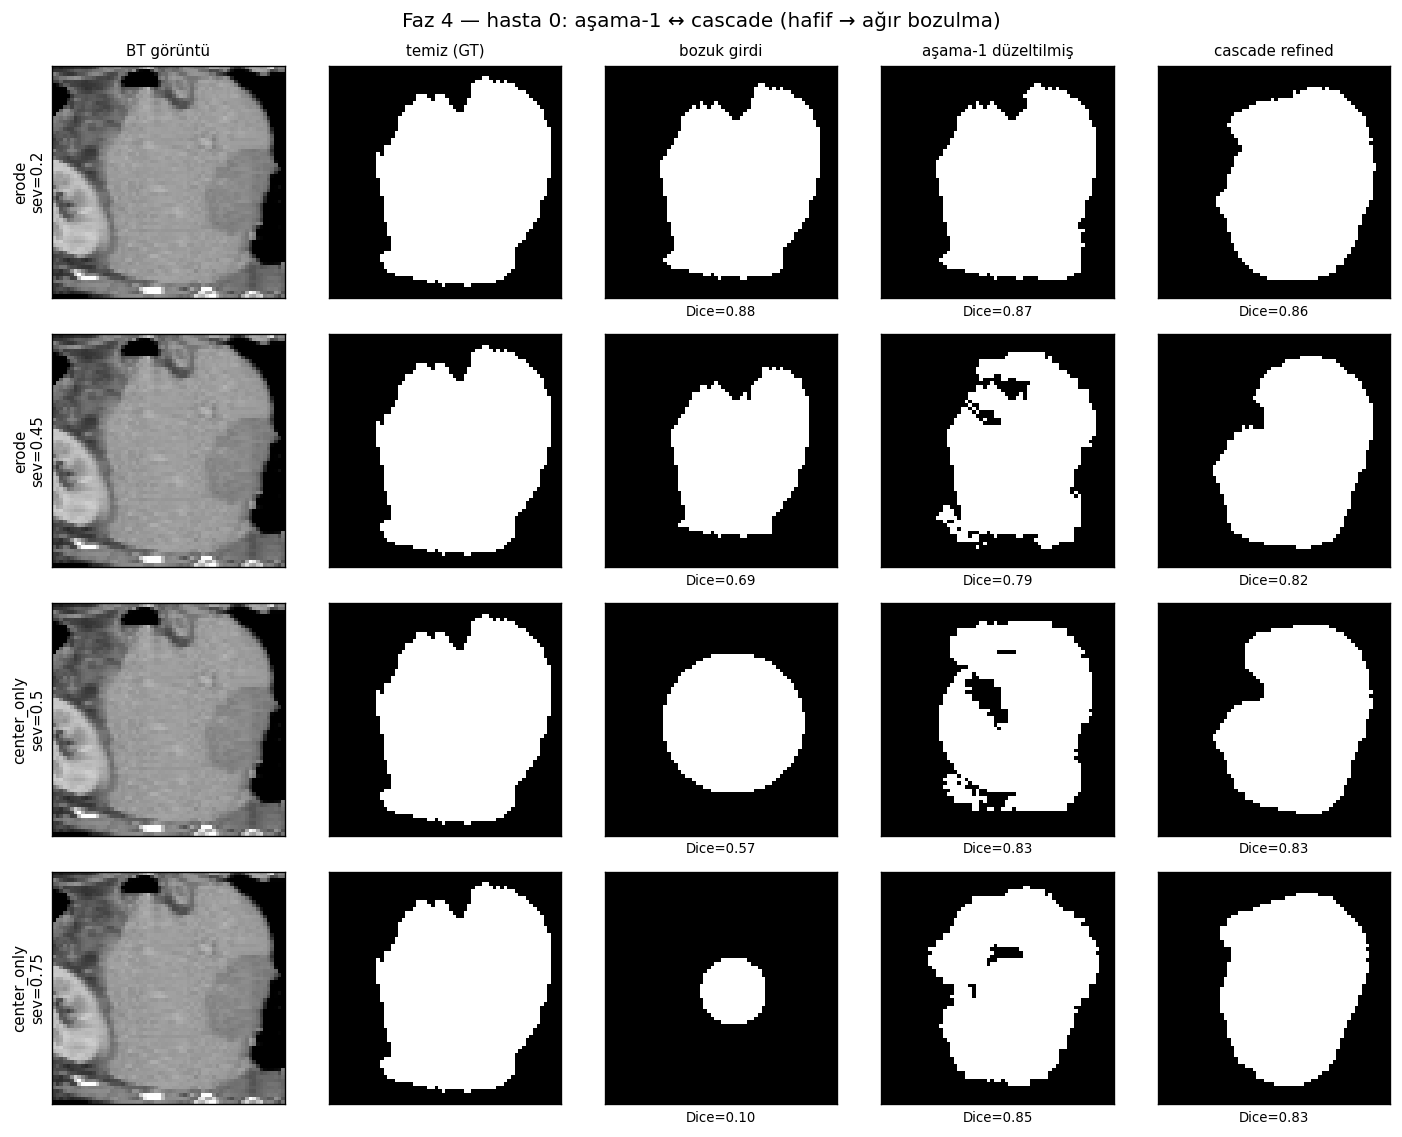

In [14]:
if cascade is not None:
    gt = clean_masks[PANEL_IDX].astype(bool); img = clean_images[PANEL_IDX]
    specs = [('erode', 0.2), ('erode', 0.45), ('center_only', 0.5), ('center_only', 0.75)]
    zc = gt.shape[0] // 2
    cols = ['BT görüntü', 'temiz (GT)', 'bozuk girdi', 'aşama-1 düzeltilmiş', 'cascade refined']
    fig, axes = plt.subplots(len(specs), 5, figsize=(2.4 * 5, 2.4 * len(specs)), squeeze=False)
    rows = []
    for ri, (name, sev) in enumerate(specs):
        b = np.asarray(ALL_FNS[name](gt, sev, np.random.default_rng(SEED))) > 0
        d_true = float(_dice(gt, b))
        x = torch.from_numpy(np.stack([img, b.astype('float32')])[None]).float().to(device)
        with torch.no_grad():
            corrected, fp, fn = cascade.stage1_products(x)
            logits, _, _ = cascade.refiner.forward(cascade.refiner_input(corrected, fp, fn))
            refined = (torch.sigmoid(logits) > 0.5)
        corr_np = (corrected[0, 0] > 0.5).cpu().numpy(); ref_np = refined[0, 0].cpu().numpy()
        d_corr = float(_dice(gt, corr_np)); d_ref = float(_dice(gt, ref_np))
        rows.append({'bozulma': f'{name}/{sev}', 'gerçek Dice': round(d_true, 3),
                     'düzeltilmiş (GT)': round(d_corr, 3), 'refined (GT)': round(d_ref, 3),
                     'kazanç': round(d_ref - d_corr, 3)})
        axes[ri, 0].imshow(img[zc], cmap='gray'); axes[ri, 1].imshow(gt[zc], cmap='gray')
        axes[ri, 2].imshow(b[zc], cmap='gray'); axes[ri, 3].imshow(corr_np[zc], cmap='gray')
        axes[ri, 4].imshow(ref_np[zc], cmap='gray')
        for ci in range(5):
            axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
            if ri == 0: axes[ri, ci].set_title(cols[ci], fontsize=9)
        axes[ri, 0].set_ylabel(f'{name}\nsev={sev}', fontsize=9)
        axes[ri, 2].set_xlabel(f'Dice={d_true:.2f}', fontsize=8)
        axes[ri, 3].set_xlabel(f'Dice={d_corr:.2f}', fontsize=8)
        axes[ri, 4].set_xlabel(f'Dice={d_ref:.2f}', fontsize=8)
    fig.suptitle(f'Faz 4 — hasta {PANEL_IDX}: aşama-1 ↔ cascade (hafif → ağır bozulma)', fontsize=12)
    fig.tight_layout()
    out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz4_panel.png'
    fig.savefig(out, dpi=150, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
    display(pd.DataFrame(rows))

## Faz 5 — Toplu metot karşılaştırması, çok-örnek ve 3B görselleştirme

Önceki fazlar metotları tek tek inceledi. Bu bölüm üç ana metodu **aynı tabloda, tüm test
kümesi üzerinden** karşılaştırır ve çok sayıda hasta/bozulma örneğini (2B + 3B) yan yana gösterir:

1. **Geçmiş (saf VAR reconstruction)** — yalnızca şekil girişi; düzeltilmiş maske üretmez,
   yalnızca bir kalite sinyali (`recon_dice` ρ) verir.
2. **FP/FN refiner'sız (Faz-3, `g_var`)** — `[görüntü, bozuk maske]` → FP/FN → düzeltilmiş maske.
3. **FP/FN refiner'lı (Faz-4 cascade, `h_cascade`)** — aşama-1 donuk + ikinci VAE ile ek düzeltme.

Her metot için ortalama **Dice** (girdi → düzeltilmiş), ortalama **kenar hatası ASSD**
(girdi → düzeltilmiş) ve **kalite sinyali** (GT-free skor ↔ gerçek Dice, Spearman ρ) raporlanır.
Tüm sayılar bozuk satırlar üzerinden (temiz hacimler hariç), tüm test hastalarında.

In [15]:
# --- Faz 5a: toplu metot karşılaştırması (tüm test, bozuk satırlar) ---
from quality.surface_metrics import assd as _assd

def _dice_np(a, b):
    a = a.astype(bool); b = b.astype(bool)
    s = int(a.sum()) + int(b.sum())
    return 1.0 if s == 0 else 2.0 * float((a & b).sum()) / s

deg_idx = np.where(~is_clean)[0]
print('toplu değerlendirme: %d bozuk hacim (tüm test hastaları)' % len(deg_idx))

@torch.no_grad()
def _gvar_corrected(model, bb, ii):
    x = torch.from_numpy(np.stack([ii, bb], axis=1).astype('float32')).to(device)
    fp, fn = model.predict_fpfn(x)
    corr = correct_mask(x[:, 1:2], fp, fn)
    return (corr[:, 0] > 0.5).cpu().numpy()

@torch.no_grad()
def _cascade_refined(model, bb, ii):
    x = torch.from_numpy(np.stack([ii, bb], axis=1).astype('float32')).to(device)
    corrected, fp, fn = model.stage1_products(x)
    logits, _, _ = model.refiner.forward(model.refiner_input(corrected, fp, fn))
    return (torch.sigmoid(logits)[:, 0] > 0.5).cpu().numpy()

def _eval_corrector(fn_corr, model, B=8):
    d_in, d_out, a_in, a_out = [], [], [], []
    for s in range(0, len(deg_idx), B):
        idx = deg_idx[s:s + B]
        out = fn_corr(model, broken[idx].astype('float32'), images[idx].astype('float32'))
        for j, gi in enumerate(idx):
            ref = clean_ref[gi].astype(bool)
            d_in.append(_dice_np(broken[gi], ref)); d_out.append(_dice_np(out[j], ref))
            a_in.append(float(_assd(broken[gi], ref))); a_out.append(float(_assd(out[j], ref)))
    return (np.array(d_in), np.array(d_out),
            np.array(a_in, dtype=float), np.array(a_out, dtype=float))

toplu_rows = []
# 1) Geçmiş: saf VAR reconstruction — düzeltme yok, yalnız QC sinyali
if 'VAR' in recon_results:
    rd = recon_results['VAR']['summary']['recon_dice']['global']['spearman']
    toplu_rows.append({'metot': 'Geçmiş (saf VAR recon)', 'düzeltme': 'yok',
                       'Dice girdi': np.nan, 'Dice çıktı': np.nan, 'ΔDice': np.nan,
                       'ASSD girdi': np.nan, 'ASSD çıktı': np.nan, 'ΔASSD': np.nan,
                       'kalite ρ (skor)': round(rd, 3), 'skor adı': 'recon_dice'})
# 2) FP/FN refiner'sız (g_var)
if 'G-VAR/ikili' in fpfn_results:
    di, do, ai, ao = _eval_corrector(_gvar_corrected, fpfn_results['G-VAR/ikili']['model'])
    ed = fpfn_results['G-VAR/ikili']['summary']['est_dice']['global']['spearman']
    toplu_rows.append({'metot': 'FP/FN refiner\'sız (Faz-3)', 'düzeltme': 'var',
                       'Dice girdi': round(float(di.mean()), 3), 'Dice çıktı': round(float(do.mean()), 3),
                       'ΔDice': round(float((do - di).mean()), 3),
                       'ASSD girdi': round(float(np.nanmean(ai)), 3), 'ASSD çıktı': round(float(np.nanmean(ao)), 3),
                       'ΔASSD': round(float(np.nanmean(ao - ai)), 3),
                       'kalite ρ (skor)': round(ed, 3), 'skor adı': 'est_dice'})
# 3) FP/FN refiner'lı (cascade)
if cascade is not None:
    di, do, ai, ao = _eval_corrector(_cascade_refined, cascade)
    ed = csummary['est_dice']['global']['spearman']
    toplu_rows.append({'metot': 'FP/FN refiner\'lı (Faz-4 cascade)', 'düzeltme': 'var',
                       'Dice girdi': round(float(di.mean()), 3), 'Dice çıktı': round(float(do.mean()), 3),
                       'ΔDice': round(float((do - di).mean()), 3),
                       'ASSD girdi': round(float(np.nanmean(ai)), 3), 'ASSD çıktı': round(float(np.nanmean(ao)), 3),
                       'ΔASSD': round(float(np.nanmean(ao - ai)), 3),
                       'kalite ρ (skor)': round(ed, 3), 'skor adı': 'est_dice'})

df_toplu = pd.DataFrame(toplu_rows)
display(df_toplu)
df_toplu.to_csv(PROJECT_ROOT / 'outputs' / 'rapor_var_faz5_toplu.csv', index=False)
print('Okuma: Dice çıktı ↑ ve ASSD çıktı ↓ daha iyi düzeltme; kalite ρ ↑ daha iyi GT-free sinyal.')
print('Geçmiş metot maske DÜZELTMEZ (yalnız QC sinyali verir), o yüzden Dice/ASSD sütunları boş.')

toplu değerlendirme: 235 bozuk hacim (tüm test hastaları)
Okuma: Dice çıktı ↑ ve ASSD çıktı ↓ daha iyi düzeltme; kalite ρ ↑ daha iyi GT-free sinyal.
Geçmiş metot maske DÜZELTMEZ (yalnız QC sinyali verir), o yüzden Dice/ASSD sütunları boş.


,metot,düzeltme,Dice girdi,Dice çıktı,ΔDice,ASSD girdi,ASSD çıktı,ΔASSD,kalite ρ (skor),skor adı
0,Geçmiş (saf VAR recon),yok,NaN,NaN,NaN,NaN,NaN,NaN,0.866,recon_dice
1,FP/FN refiner'sız (Faz-3),var,0.702,0.857,0.155,3.243,1.553,-1.690,0.962,est_dice
2,FP/FN refiner'lı (Faz-4 cascade),var,0.702,0.889,0.188,3.243,1.247,-1.996,0.962,est_dice


### Faz 5b — çok hasta × çok bozulma: düzeltme + Dice/ASSD (2B)

Farklı hastalarda farklı bozulma tipleri (erozyon ağırlıklı, ama tüm tipler) uygulanıp her iki
düzeltici (refiner'sız g_var ↔ refiner'lı cascade) yan yana gösterilir. Her düzeltme panelinin
altında **gerçek Dice ve kenar hatası ASSD** yazılıdır; böylece hangi metodun hangi bozulmada ne
kadar düzelttiği sayısal olarak okunur.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz5_cok_ornek.png


,hasta,bozulma,Dice girdi,ASSD girdi,Dice refsız,ASSD refsız,Dice refli,ASSD refli
0,0,erode/0.3,0.750,3.36,0.809,2.46,0.825,2.47
1,0,heavy_erode/0.4,0.095,15.32,0.837,2.40,0.813,2.62
2,0,center_only/0.55,0.452,8.57,0.825,2.58,0.818,2.58
3,0,dilate/0.4,0.761,3.97,0.780,2.58,0.851,2.10
4,0,boundary_noise/0.5,0.829,2.03,0.806,2.16,0.871,1.88
5,0,add_false_positive/0.4,0.960,0.58,0.963,0.81,0.899,1.48
6,3,erode/0.3,0.561,3.59,0.826,1.49,0.877,1.33
7,3,heavy_erode/0.4,0.000,NaN,0.861,1.37,0.884,1.21
8,3,center_only/0.55,0.607,4.72,0.886,1.05,0.880,1.26
9,3,dilate/0.4,0.670,4.05,0.806,1.74,0.874,1.34


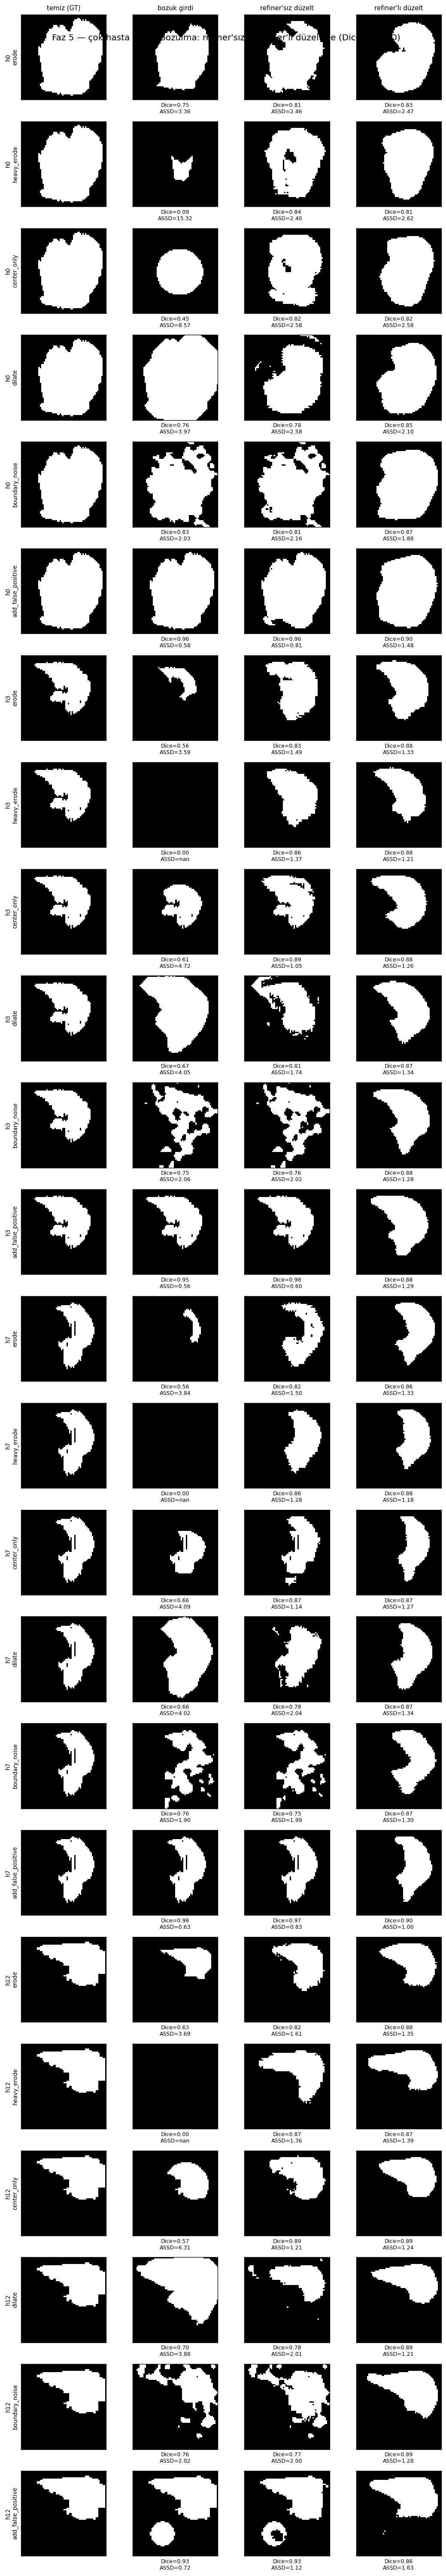

In [16]:
# Çok hasta × çok bozulma — her hücrede Dice + ASSD
VIZ_PATIENTS = [0, 3, 7, 12]                 # istenirse değiştir
VIZ_DEGS = [('erode', 0.30), ('heavy_erode', 0.40), ('center_only', 0.55),
            ('dilate', 0.40), ('boundary_noise', 0.50), ('add_false_positive', 0.40)]

have_gvar = 'G-VAR/ikili' in fpfn_results
have_cas = cascade is not None
rowspecs = []
for pid in VIZ_PATIENTS:
    for (nm, sev) in VIZ_DEGS:
        rowspecs.append((pid, nm, sev))

cols = ['temiz (GT)', 'bozuk girdi', 'refiner\'sız düzelt', 'refiner\'lı düzelt']
fig, axes = plt.subplots(len(rowspecs), 4, figsize=(2.3 * 4, 2.1 * len(rowspecs)), squeeze=False)
viz_rows = []
for ri, (pid, nm, sev) in enumerate(rowspecs):
    gt = clean_masks[pid].astype(bool); img = clean_images[pid]
    b = np.asarray(ALL_FNS[nm](gt, sev, np.random.default_rng(SEED + pid))) > 0
    d_in = _dice_np(gt, b); a_in = float(_assd(b, gt))
    zc = gt.shape[0] // 2
    axes[ri, 0].imshow(gt[zc], cmap='gray'); axes[ri, 1].imshow(b[zc], cmap='gray')
    rec = {'hasta': pid, 'bozulma': f'{nm}/{sev}', 'Dice girdi': round(d_in, 3), 'ASSD girdi': round(a_in, 2)}
    if have_gvar:
        cg = _gvar_corrected(fpfn_results['G-VAR/ikili']['model'],
                             b[None].astype('float32'), img[None].astype('float32'))[0]
        dg = _dice_np(gt, cg); ag = float(_assd(cg, gt))
        axes[ri, 2].imshow(cg[zc], cmap='gray')
        axes[ri, 2].set_xlabel(f'Dice={dg:.2f}\nASSD={ag:.2f}', fontsize=7.5)
        rec['Dice refsız'] = round(dg, 3); rec['ASSD refsız'] = round(ag, 2)
    if have_cas:
        cc = _cascade_refined(cascade, b[None].astype('float32'), img[None].astype('float32'))[0]
        dc = _dice_np(gt, cc); ac = float(_assd(cc, gt))
        axes[ri, 3].imshow(cc[zc], cmap='gray')
        axes[ri, 3].set_xlabel(f'Dice={dc:.2f}\nASSD={ac:.2f}', fontsize=7.5)
        rec['Dice refli'] = round(dc, 3); rec['ASSD refli'] = round(ac, 2)
    for ci in range(4):
        axes[ri, ci].set_xticks([]); axes[ri, ci].set_yticks([])
        if ri == 0: axes[ri, ci].set_title(cols[ci], fontsize=9)
    axes[ri, 0].set_ylabel(f'h{pid}\n{nm}', fontsize=8)
    axes[ri, 1].set_xlabel(f'Dice={d_in:.2f}\nASSD={a_in:.2f}', fontsize=7.5)
    viz_rows.append(rec)
fig.suptitle('Faz 5 — çok hasta × çok bozulma: refiner\'sız ↔ refiner\'lı düzeltme (Dice + ASSD)', fontsize=12)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz5_cok_ornek.png'
fig.savefig(out, dpi=140, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
display(pd.DataFrame(viz_rows))

### Faz 5c — tüm hastalarda erozyon taraması (toplu eğri)

Tek bir erozyon tipinde (heavy_erode) tüm test hastaları taranır; her hastada artan şiddet
uygulanıp refiner'sız ve refiner'lı düzeltmenin gerçek Dice'ı çizilir. Bozulma ağırlaştıkça
(gerçek Dice düştükçe) düzelticilerin maskeyi ne kadar toparladığı tüm popülasyonda görülür.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz5_erozyon_tarama.png
girdi ort Dice=0.111 | refiner'sız ort=0.871 | refiner'lı ort=0.882


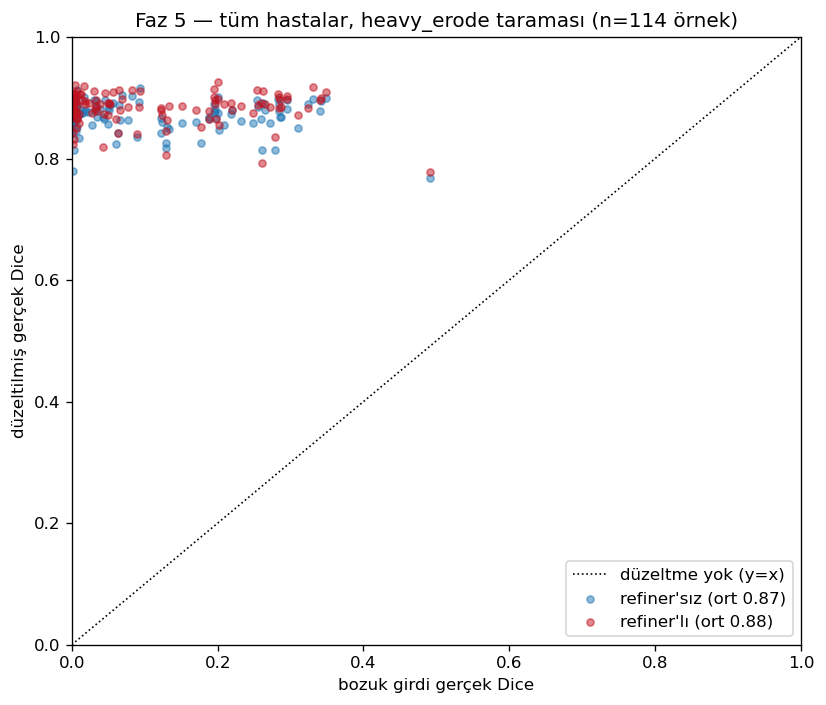

In [17]:
# Tüm hastalarda erozyon taraması: gerçek Dice vs düzeltilmiş Dice
SWEEP_NAME = 'heavy_erode'
SWEEP_SEVS = np.linspace(0.20, 0.55, 5)
xs, yg, yc = [], [], []
for pid, (gt_, img_) in enumerate(zip(clean_masks, clean_images)):
    gt_ = gt_.astype(bool)
    for sev in SWEEP_SEVS:
        b = np.asarray(ALL_FNS[SWEEP_NAME](gt_, float(sev), np.random.default_rng(SEED + pid))) > 0
        if not (0 < int(b.sum()) < gt_.size): continue
        d_true = _dice_np(gt_, b)
        xs.append(d_true)
        if have_gvar:
            cg = _gvar_corrected(fpfn_results['G-VAR/ikili']['model'],
                                 b[None].astype('float32'), img_[None].astype('float32'))[0]
            yg.append(_dice_np(gt_, cg))
        if have_cas:
            cc = _cascade_refined(cascade, b[None].astype('float32'), img_[None].astype('float32'))[0]
            yc.append(_dice_np(gt_, cc))
xs = np.array(xs)
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], 'k:', lw=1, label='düzeltme yok (y=x)')
if have_gvar:
    ax.scatter(xs, yg, s=18, alpha=0.5, c='#1f77b4', label=f"refiner'sız (ort {np.mean(yg):.2f})")
if have_cas:
    ax.scatter(xs, yc, s=18, alpha=0.5, c='#c1121f', label=f"refiner'lı (ort {np.mean(yc):.2f})")
ax.set_xlabel('bozuk girdi gerçek Dice'); ax.set_ylabel('düzeltilmiş gerçek Dice')
ax.set_title(f'Faz 5 — tüm hastalar, {SWEEP_NAME} taraması (n={len(xs)} örnek)')
ax.legend(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.tight_layout()
out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz5_erozyon_tarama.png'
fig.savefig(out, dpi=140, bbox_inches='tight'); print('kaydedildi:', out)
print(f'girdi ort Dice={xs.mean():.3f}' +
      (f" | refiner'sız ort={np.mean(yg):.3f}" if have_gvar else '') +
      (f" | refiner'lı ort={np.mean(yc):.3f}" if have_cas else ''))
plt.show()

### Faz 5d — 3B izoyüzey görselleştirme (cascade hata lokalizasyonu)

2B kesitler hacmin tamamını göstermez. Burada `skimage.measure.marching_cubes` ile birkaç bozuk
karaciğer, **3B izoyüzey** olarak çizilir: gri = bozuk maske yüzeyi, altın = gerçek hata bölgesi
(`bozuk XOR temiz`), kırmızı = cascade'in işaretlediği hata (`|refine − bozuk| > 0.5`). Bu hücre
doğrudan notebook içinde 3B üretir; açı/örnek değiştirmek için `VIZ3D_*` değişkenlerini düzenle.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\rapor_var_faz5_3b.png


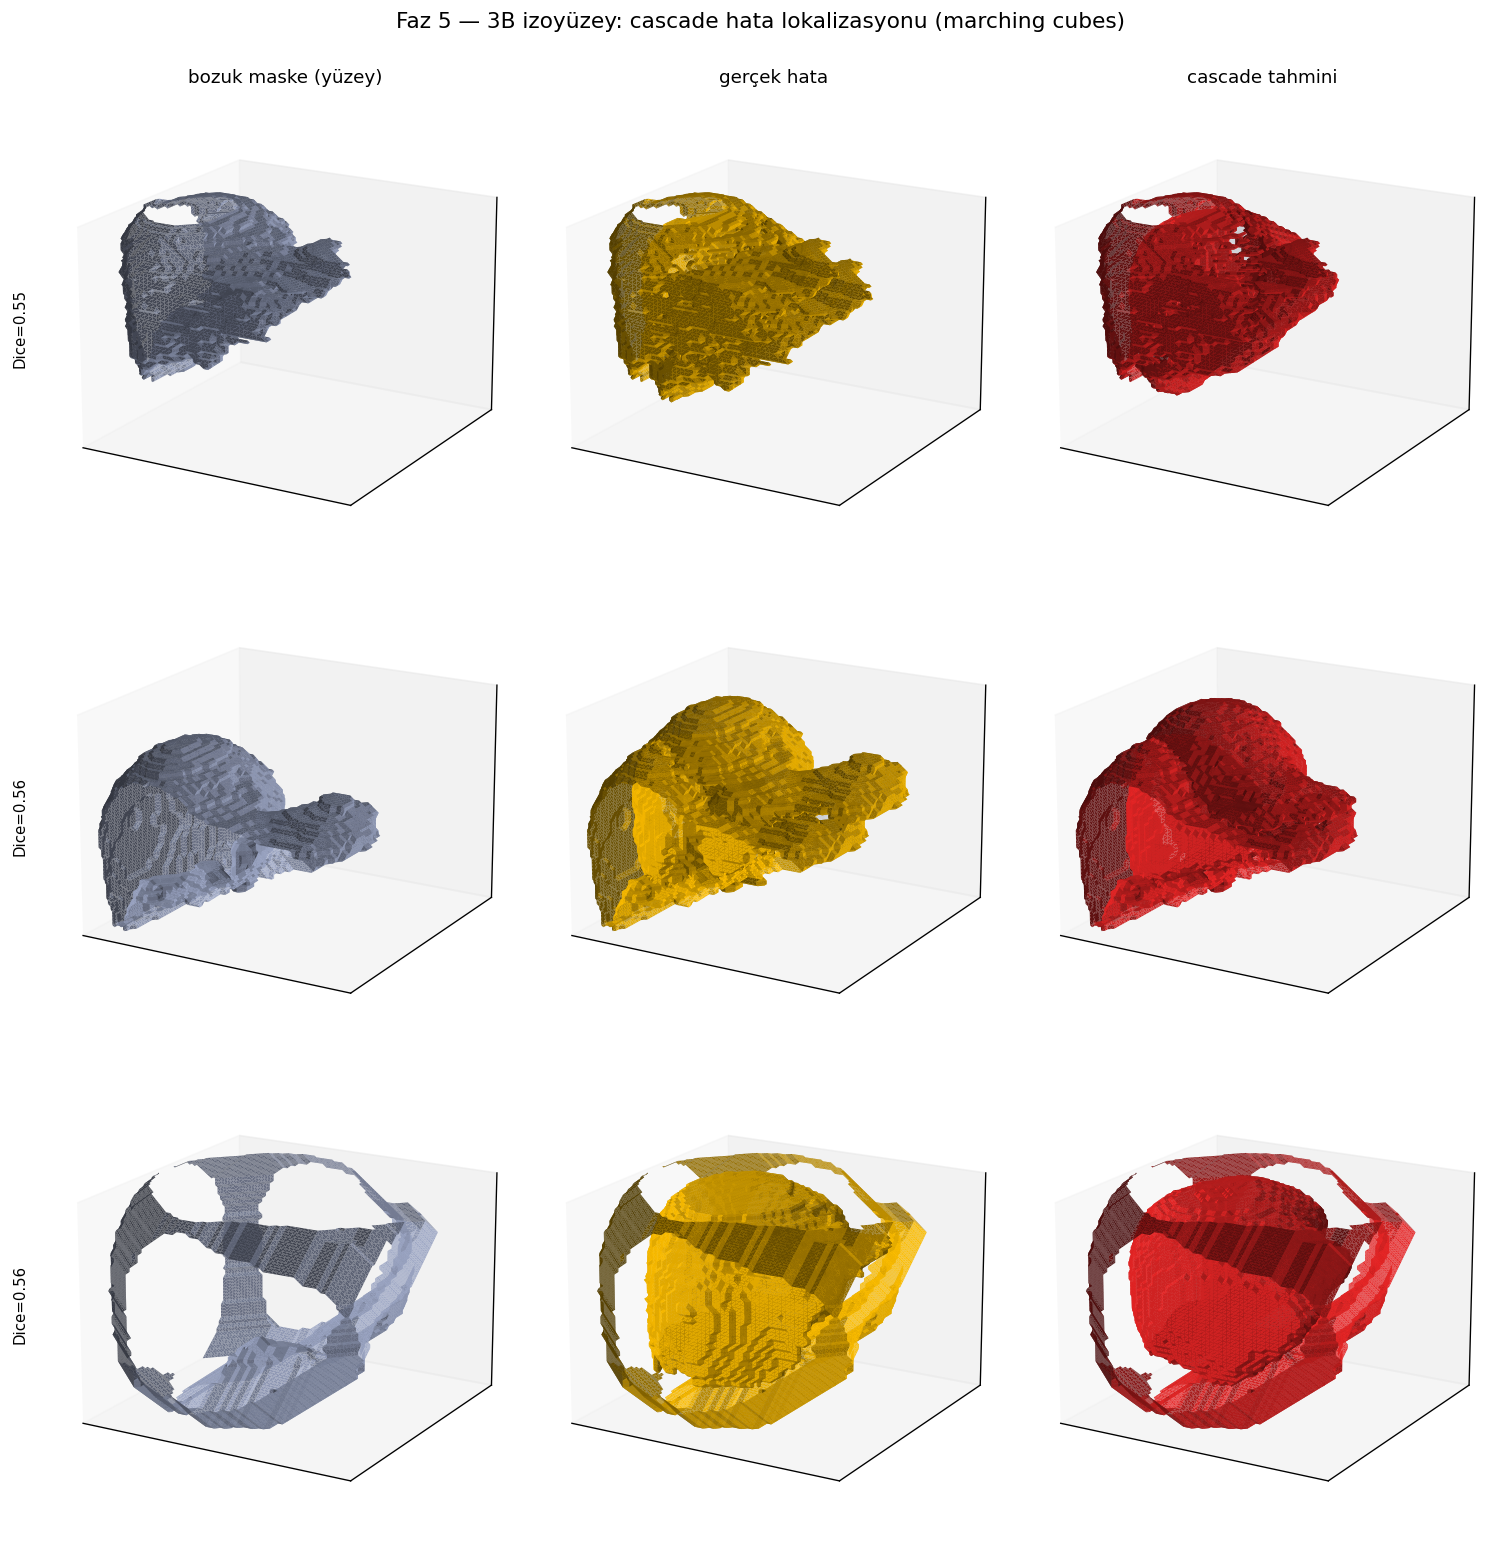

In [18]:
from skimage import measure
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (3d projeksiyonu kaydeder)

VIZ3D_BAND = (0.55, 0.85)    # orta-zor bant (şekil büyük ölçüde sağlam, hata lokalize)
VIZ3D_N = 3                  # kaç örnek
VIZ3D_ELEV, VIZ3D_AZIM = 18, -60

def _add_surf(ax, vol, color, alpha):
    if int(vol.sum()) < 10: return
    try:
        v, f, _, _ = measure.marching_cubes(vol.astype('float32'), level=0.5)
    except (ValueError, RuntimeError):
        return
    ax.plot_trisurf(v[:, 0], v[:, 1], f, v[:, 2], color=color, alpha=alpha,
                    linewidth=0, antialiased=True, shade=True)

@torch.no_grad()
def _cascade_softmap(model, bb, ii):
    x = torch.from_numpy(np.stack([ii, bb], axis=1).astype('float32')).to(device)
    ref = model.predict_reference(x)[:, 0]
    bt = torch.from_numpy(bb.astype('float32')).to(device)
    return (ref - bt).abs().cpu().numpy()

if cascade is not None:
    cand = [i for i in deg_idx if VIZ3D_BAND[0] <= true_dice[i] <= VIZ3D_BAND[1]]
    cand.sort(key=lambda i: true_dice[i])
    picks3d = []
    for i in cand:
        err = broken[i].astype(bool) ^ clean_ref[i].astype(bool)
        if 100 < int(err.sum()) < 0.4 * err.size:
            picks3d.append(i)
        if len(picks3d) == VIZ3D_N: break
    smaps = _cascade_softmap(cascade, broken[picks3d].astype('float32'), images[picks3d].astype('float32'))
    fig = plt.figure(figsize=(4.2 * 3, 4.4 * len(picks3d)))
    titles = ['bozuk maske (yüzey)', 'gerçek hata', 'cascade tahmini']
    for r, gi in enumerate(picks3d):
        b = broken[gi].astype(bool)
        terr = b ^ clean_ref[gi].astype(bool)
        perr = smaps[r] > 0.5
        layers = [[(b, (0.62, 0.66, 0.78), 1.0)],
                  [(b, (0.70, 0.74, 0.85), 0.15), (terr, (1.0, 0.75, 0.0), 1.0)],
                  [(b, (0.70, 0.74, 0.85), 0.15), (perr, (0.92, 0.15, 0.15), 1.0)]]
        for c in range(3):
            ax = fig.add_subplot(len(picks3d), 3, r * 3 + c + 1, projection='3d')
            for vol, col, al in layers[c]:
                _add_surf(ax, vol, col, al)
            ax.set_xlim(0, b.shape[0]); ax.set_ylim(0, b.shape[1]); ax.set_zlim(0, b.shape[2])
            ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
            ax.view_init(elev=VIZ3D_ELEV, azim=VIZ3D_AZIM)
            if r == 0: ax.set_title(titles[c], fontsize=11)
            if c == 0: ax.text2D(-0.08, 0.5, f'Dice={true_dice[gi]:.2f}', transform=ax.transAxes,
                                 fontsize=9, rotation=90, va='center')
    fig.suptitle('Faz 5 — 3B izoyüzey: cascade hata lokalizasyonu (marching cubes)', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    out = PROJECT_ROOT / 'outputs' / 'rapor_var_faz5_3b.png'
    fig.savefig(out, dpi=130, bbox_inches='tight'); print('kaydedildi:', out); plt.show()
else:
    print('cascade yok — 3B hücre atlandı')

## Bulguların özeti

Faz-faz karşılaştırmayı tek tabloda toplar. Her fazın birincil QC metriği ve o fazda VAR
bileşeninin etkisi dürüst biçimde özetlenir.

In [19]:
summary_rows = []
# Faz 1-2 (reconstruction QC)
for lbl in ['VQ (taban)', 'VAR']:
    if lbl in recon_results:
        rd = recon_results[lbl]['summary']['recon_dice']['global']['spearman']
        summary_rows.append({'faz': 'Faz1 recon', 'model': lbl, 'birincil QC': 'recon_dice ρ', 'değer': round(rd, 3)})
for lbl in ['VAR+GAN', 'VAR+GAN dengeli']:
    if lbl in gan_results:
        rd = gan_results[lbl]['summary']['recon_dice']['global']['spearman']
        summary_rows.append({'faz': 'Faz2 GAN', 'model': lbl, 'birincil QC': 'recon_dice ρ', 'değer': round(rd, 3)})
# Faz 3 (est_dice ρ)
for lbl in [l for l, *_ in FPFN_REGISTRY if l in fpfn_results]:
    ed = fpfn_results[lbl]['summary']['est_dice']['global']['spearman']
    summary_rows.append({'faz': 'Faz3 FP/FN', 'model': lbl, 'birincil QC': 'est_dice ρ', 'değer': round(ed, 3)})
# Faz 4
if cascade is not None:
    summary_rows.append({'faz': 'Faz4 cascade', 'model': 'refined (doğruluk)',
                         'birincil QC': 'Dice kazanç', 'değer': round(acc['dice_gain'], 4)})
    summary_rows.append({'faz': 'Faz4 cascade', 'model': 'est_dice (QC, değişmez)',
                         'birincil QC': 'est_dice ρ', 'değer': round(csummary['est_dice']['global']['spearman'], 3)})
display(pd.DataFrame(summary_rows))

,faz,model,birincil QC,değer
0,Faz1 recon,VAR,recon_dice ρ,0.8660
1,Faz2 GAN,VAR+GAN,recon_dice ρ,0.8440
2,Faz2 GAN,VAR+GAN dengeli,recon_dice ρ,0.8730
3,Faz3 FP/FN,G-ikili/VQ,est_dice ρ,0.9480
4,Faz3 FP/FN,G-ikili/SimVQ,est_dice ρ,0.9560
5,Faz3 FP/FN,G-SDF/VQ,est_dice ρ,0.9300
6,Faz3 FP/FN,G-SDF/SimVQ,est_dice ρ,0.9430
7,Faz3 FP/FN,G-VAR/ikili,est_dice ρ,0.9620
8,Faz4 cascade,refined (doğruluk),Dice kazanç,0.0324
9,Faz4 cascade,"est_dice (QC, değişmez)",est_dice ρ,0.9620


**Özet değerlendirme.**

- **Faz 1:** VAR tokenizer reconstruction'da düz VQ'yu geçer ve kod defteri sağlığını (perplexity)
  belirgin iyileştirir; ancak reconstruction-tabanlı QC (recon_dice ρ) pratikte eşittir. "En iyi
  reconstruction ≠ en iyi QC" gözlemi tekrar doğrulanır.
- **Faz 2:** GAN terimi reconstruction QC'yi düz VAR'ın üzerine çıkarmaz (dengeli koşuda en fazla
  gürültü-aralığında oynar); quant_error QC zayıflar. Reconstruction-tarafı QC platoya ulaşır.
- **Faz 3:** VAR omurgalı FP/FN, tüm FP/FN varyantları içinde hem est_dice ρ hem ASSD'de en iyidir —
  VAR'ın yalnız reconstruction'da değil **QC'de** de öne çıktığı ilk fazdır. QC farkı küçüktür
  (FP/FN est_dice tavana yakındır), asıl belirgin kazanç ASSD'dedir (kenar hatası azalır).
- **Faz 4:** İkinci VAE referans maskenin doğruluğunu artırır (Dice ve ASSD iyileşir, kimlik-tuzağına
  düşmez); ancak GT-free kalite kestirimini (est_dice ρ) iyileştirmez ve cascade'e özgü sinyaller
  zayıftır. "Doğruluk ↑ ≠ QC ↑" ayrımı net biçimde gözlenir.